# Football Match Outcome Prediction with xG and Elo

Predicting home win / draw / away win in six European leagues (2014/15–2018/19) using only information available before kickoff: recent form, expected goals (xG), league position, and Elo ratings.

## Dataset Overview

This project uses historical football match statistics from six European leagues, covering the 2014/15–2018/19 seasons.

**Source:** [Football Data: Expected Goals and Other Metrics — Kaggle](https://www.kaggle.com/datasets/slehkyi/extended-football-stats-for-european-leagues-xg)

The original dataset contains team-level match records, meaning each row represents one team's performance in a particular match.

The 2019/20 season was excluded due to incomplete match coverage.

### Data Dictionary

| Feature | Description |
|---|---|
| `league` | Competition in which the match was played |
| `season` | Starting calendar year of the football season |
| `date` | Match date and time |
| `team` | Name of the team |
| `home_away` | Whether the team played at home (`h`) or away (`a`) |
| `goals_for` | Actual goals scored by the team |
| `goals_against` | Actual goals conceded |
| `points` | Points earned: 3 for a win, 1 for a draw, 0 for a loss |
| `match_result` | Win, draw, or loss from the team's perspective |
| `win_flag` | Binary indicator of a win |
| `draw_flag` | Binary indicator of a draw |
| `loss_flag` | Binary indicator of a loss |
| `xg_for` | Expected goals created based on shot quality |
| `xg_against` | Expected goals generated by the opposition |
| `expected_points` | Expected number of points earned based on the match's underlying chances |

### Engineered Features

The following features are calculated from the original statistics.

| Feature | Formula | Interpretation |
|---|---|---|
| `points_above_expected` | points − expected_points | Points earned beyond expectation |
| `goals_above_expected` | goals_for − xg_for | Goals scored beyond expectation |
| `goals_conceded_above_expected` | goals_against − xg_against | Goals conceded beyond expectation |
| `xg_difference` | xg_for − xg_against | Difference in expected goals |
| `goal_difference` | goals_for − goals_against | Actual goal difference |

### Prediction Methodology

The objective is to predict match outcomes: Home Win, Draw, or Away Win.

Models will be compared using recent results, expected goals, expected points, and combinations of these features.

**Data Split (Chronological):**
- **Training (2014/15–2016/17):** Train the models.
- **Validation (2017/18):** Select the best model and tune parameters.
- **Test (2018/19):** Evaluate final predictive performance on unseen matches.

After model selection, the model may be retrained on both training and validation seasons before final testing.

To prevent data leakage, predictive features will use only information available before each match.

### Data Cleaning – Excluding Incomplete Seasons

The 2019/20 season was excluded from the analysis due to incomplete match coverage in some leagues, particularly Ligue 1 and Serie A.

This decision ensures that the analysis uses complete seasons and avoids potential biases caused by unequal match coverage across teams and leagues.

The final dataset covers five seasons, from 2014/15 through 2018/19.

In [1]:
import pandas as pd

# Load original dataset
df_raw = pd.read_csv("../data/understat_per_game.csv")

# Select and rename relevant columns
column_names = {
    "league": "league",
    "year": "season",
    "date": "date",
    "team": "team",
    "h_a": "home_away",

    "scored": "goals_for",
    "missed": "goals_against",
    "pts": "points",
    "result": "match_result",
    "wins": "win_flag",
    "draws": "draw_flag",
    "loses": "loss_flag",

    "xG": "xg_for",
    "xGA": "xg_against",
    "xpts": "expected_points"
}

df = df_raw[list(column_names.keys())].rename(
    columns=column_names
).copy()

# Convert date to datetime
df["date"] = pd.to_datetime(df["date"])

# Feature Engineering
df["points_above_expected"] = (
    df["points"] - df["expected_points"]
)

df["goals_above_expected"] = (
    df["goals_for"] - df["xg_for"]
)

df["goals_conceded_above_expected"] = (
    df["goals_against"] - df["xg_against"]
)

df["xg_difference"] = (
    df["xg_for"] - df["xg_against"]
)

df["goal_difference"] = (
    df["goals_for"] - df["goals_against"]
)

# Remove incomplete 2019/20 season
df = df[df["season"] < 2019].copy()

print(df.shape)
df.head()

(20660, 20)


,league,season,date,team,home_away,goals_for,goals_against,points,match_result,win_flag,draw_flag,loss_flag,xg_for,xg_against,expected_points,points_above_expected,goals_above_expected,goals_conceded_above_expected,xg_difference,goal_difference
0,Bundesliga,2014,2014-08-22 19:30:00,Bayern Munich,h,2,1,3,w,1,0,0,2.57012,1.198420,2.3486,0.6514,-0.57012,-0.198420,1.371700,1
1,Bundesliga,2014,2014-08-30 17:30:00,Bayern Munich,a,1,1,1,d,0,1,0,1.50328,1.307950,1.5143,-0.5143,-0.50328,-0.307950,0.195330,0
2,Bundesliga,2014,2014-09-13 14:30:00,Bayern Munich,h,2,0,3,w,1,0,0,1.22987,0.310166,2.1588,0.8412,0.77013,-0.310166,0.919704,2
3,Bundesliga,2014,2014-09-20 14:30:00,Bayern Munich,a,0,0,1,d,0,1,0,1.03519,0.203118,2.1367,-1.1367,-1.03519,-0.203118,0.832072,0
4,Bundesliga,2014,2014-09-23 19:00:00,Bayern Munich,h,4,0,3,w,1,0,0,3.48286,0.402844,2.9287,0.0713,0.51714,-0.402844,3.080016,4


### Data Quality Assessment

The dataset was checked for missing values, duplicate records, and match coverage across leagues and seasons.

**Findings:**
- No missing values were detected.
- No fully duplicated rows were found.
- Match counts are consistent across all five seasons and match the expected league schedules.

The dataset is suitable for further analysis, subject to verification of home-away match pairing.

In [2]:
# 1. Missing values
print(df.isna().sum())

# 2. Exact duplicate rows
print("Duplicates:", df.duplicated().sum())

# 3. Records per season and league
print(
    df.groupby(["season", "league"])
      .size()
      .unstack()
)

league                           0
season                           0
date                             0
team                             0
home_away                        0
goals_for                        0
goals_against                    0
points                           0
match_result                     0
win_flag                         0
draw_flag                        0
loss_flag                        0
xg_for                           0
xg_against                       0
expected_points                  0
points_above_expected            0
goals_above_expected             0
goals_conceded_above_expected    0
xg_difference                    0
goal_difference                  0
dtype: int64
Duplicates: 0
league  Bundesliga  EPL  La_liga  Ligue_1  RFPL  Serie_A
season                                                  
2014           612  760      760      760   480      760
2015           612  760      760      760   480      760
2016           612  760      760      760   4

### Exploratory Data Analysis — xG and Team Performance

Before building our prediction models, we examine the relationship between expected goal difference (xG for minus xG against) and actual points earned.

We use the training seasons (2014–2016) to explore whether teams with stronger underlying performance tend to earn more points.

This helps motivate the use of xG-based features in our prediction models.

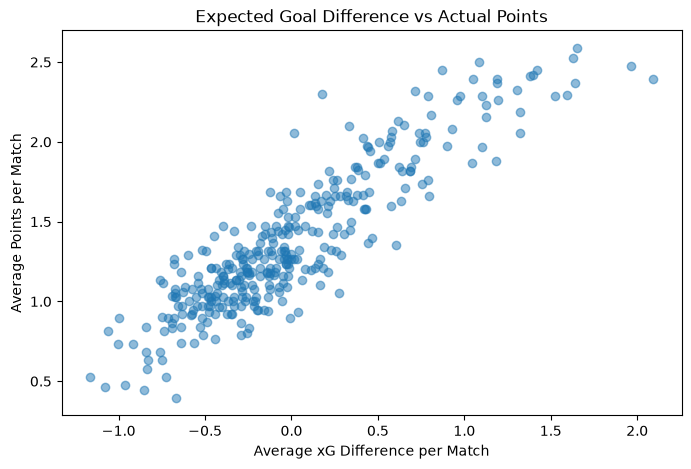

Correlation: 0.900


In [3]:
import matplotlib.pyplot as plt

# Use only training seasons
eda_df = df[df["season"] <= 2016]

# Calculate average performance for each team and season
team_stats = eda_df.groupby(
    ["league", "season", "team"]
)[["xg_difference", "points"]].mean().reset_index()

# Plot the relationship
plt.figure(figsize=(8, 5))

plt.scatter(
    team_stats["xg_difference"],
    team_stats["points"],
    alpha=0.5
)

plt.xlabel("Average xG Difference per Match")
plt.ylabel("Average Points per Match")
plt.title("Expected Goal Difference vs Actual Points")

plt.show()

# Calculate correlation
correlation = team_stats["xg_difference"].corr(team_stats["points"])
print(f"Correlation: {correlation:.3f}")

### EDA (Exploratory Data Analysis) Findings — Expected Goals and Actual Performance

The scatter plot shows a strong positive relationship between average expected goal difference and average points earned per match.

Teams that consistently generate more expected goals than their opponents tend to earn more points, while teams with negative xG differences generally perform worse.

However, some variation remains, indicating that expected goals do not fully explain actual match outcomes.

**Key Takeaway:** This relationship supports our decision to include xG-based features in the prediction models. However, a season-level correlation does not necessarily translate into accurate individual match predictions.

### Feature Engineering – Rolling Performance Metrics

To capture each team's recent form, we calculated rolling averages of 11 performance metrics over the previous five matches.

- Calculations are performed separately for each team.
- `shift(1)` excludes the current match to prevent data leakage.
- `rolling(5, min_periods=1)` allows averages based on fewer than five previous matches.
- Match history is carried across seasons.

A reusable function and loop were used to generate all features efficiently.

In [4]:
# Sort matches chronologically for each team
df = df.sort_values(
    by=["league", "team", "date"]
)

# Calculate rolling averages using only previous matches
def calculate_last5_average(series):
    previous = series.shift(1)
    return previous.rolling(window=5, min_periods=1).mean()

# Metrics used to measure recent team performance
features = [
    "points",
    "expected_points",
    "goals_for",
    "goals_against",
    "xg_for",
    "xg_against",
    "points_above_expected",
    "goals_above_expected",
    "goals_conceded_above_expected",
    "xg_difference",
    "goal_difference"
]

# Generate rolling features separately for each team
for feature in features:
    df[f"avg_{feature}_last5"] = (
        df.groupby(["league", "team"])[feature]
          .transform(calculate_last5_average)
    )

# Verify calculations using Bayern Munich's first matches
df.loc[
    df["team"] == "Bayern Munich",
    ["date", "points", "avg_points_last5",
     "xg_for", "avg_xg_for_last5"]
].head(10)

,date,points,avg_points_last5,xg_for,avg_xg_for_last5
0,2014-08-22 19:30:00,3,NaN,2.57012,NaN
1,2014-08-30 17:30:00,1,3.000000,1.50328,2.570120
2,2014-09-13 14:30:00,3,2.000000,1.22987,2.036700
3,2014-09-20 14:30:00,1,2.333333,1.03519,1.767757
4,2014-09-23 19:00:00,3,2.000000,3.48286,1.584615
5,2014-09-27 14:30:00,3,2.200000,3.46966,1.964264
6,2014-10-04 14:30:00,3,2.200000,2.69879,2.144172
7,2014-10-18 14:30:00,3,2.600000,2.49826,2.383274
8,2014-10-26 16:30:00,1,2.600000,1.20470,2.636952
9,2014-11-01 17:30:00,3,2.600000,2.64367,2.670854


### Feature Engineering – Pre-Match League Position

We compute each team's league position before every match day, resetting at the start of each season.


In [5]:
import numpy as np

# Create an empty column to store each team's position before a match
df["pre_match_position"] = np.nan

# Process each league and season separately
# This ensures that league standings reset at the start of each season
for (league, season), season_df in df.groupby(["league", "season"]):

    # Get all teams participating in the current league and season
    teams = season_df["team"].unique()

    # Initialize the standings for every team
    # Each list stores: [total points, goal difference, goals scored]
    standings = {team: [0, 0, 0] for team in teams}

    # Process matchdays in chronological order
    # normalize() removes the time component from each date
    # Games played on the same day are processed together
    for day, games in season_df.groupby(
        season_df["date"].dt.normalize(), sort=True
    ):

        # Sort teams according to their CURRENT standings
        # Python compares lists element by element:
        # 1. Total points
        # 2. Goal difference
        # 3. Goals scored
        # reverse=True puts teams with better records first
        ordered = sorted(
            teams,
            key=lambda team: standings[team],
            reverse=True
        )

        # Create a dictionary to store each team's current position
        positions = {}

        # Assign positions to teams in the sorted order
        for i, team in enumerate(ordered):

            # Assign a new rank to the first team
            # or whenever the standings differ from the previous team
            if i == 0 or standings[team] != standings[ordered[i - 1]]:
                rank = i + 1

            # Teams tied on all three metrics receive the same rank
            positions[team] = rank

        # Convert team names into their positions using the dictionary
        # Example: "Arsenal" -> 4
        positions_today = games["team"].map(positions)

        # Update the ORIGINAL DataFrame for all games on this day
        # games.index identifies the exact rows to update
        # IMPORTANT: Positions are saved BEFORE today's results
        df.loc[games.index, "pre_match_position"] = positions_today

        # Now process the actual results from today's matches
        # Each row represents one team's performance in a match
        for match in games.itertuples():

            # Add the points earned in this match
            standings[match.team][0] += match.points

            # Update the accumulated goal difference
            standings[match.team][1] += match.goal_difference

            # Update the accumulated number of goals scored
            standings[match.team][2] += match.goals_for

        # The updated standings will be used for the NEXT matchday

### Match-Level Data Preparation

The original dataset contains two records per match, one for each team. To prepare the data for match outcome prediction, home and away records were merged into a single match-level dataset.

**Matching process:**
1. Separate home and away records.
2. Join records by league, season, and match date.
3. Validate potential matches using actual goals and expected goals (xG), allowing a small tolerance for rounding differences.

The resulting dataset contains **10,330 matches**, with historical performance features for both teams.

Match-pair uniqueness will be verified separately to ensure that every home and away record is matched exactly once.

*Note: Current-match statistics are used only for identifying matching records, not as predictive features, to prevent data leakage.*

In [6]:
# Separate home and away team records
home = df[df["home_away"] == "h"]
away = df[df["home_away"] == "a"]

print(home.shape)
print(away.shape)

# Join potential opponents by league, season, and kickoff time
matches = home.merge(
    away,
    on=["league", "season", "date"],
    suffixes=("_home", "_away")
)

# Filter valid match pairs using actual and expected goals
tolerance = 0.001

matches = matches[
    # Actual goals must match from opposite perspectives
    (matches["goals_for_home"] == matches["goals_against_away"]) &
    (matches["goals_against_home"] == matches["goals_for_away"]) &

    # Expected goals must match, allowing minor rounding differences
    ((matches["xg_for_home"] - matches["xg_against_away"]).abs() < tolerance) &
    ((matches["xg_against_home"] - matches["xg_for_away"]).abs() < tolerance)
]

print(matches.shape)

keys = ["league", "season", "date"]

home_duplicates = matches.duplicated(
    subset=keys + ["team_home"]
).sum()

away_duplicates = matches.duplicated(
    subset=keys + ["team_away"]
).sum()

print("Home duplicates:", home_duplicates)
print("Away duplicates:", away_duplicates)

(10330, 32)
(10330, 32)
(10330, 61)
Home duplicates: 0
Away duplicates: 0


### Chronological Data Split

The dataset is divided by season to simulate predicting future football matches:

- **Training (2014–2016):** Model training.
- **Validation (2017):** Model selection and hyperparameter tuning.
- **Test (2018):** Final performance evaluation.

Both team-level and match-level datasets are preserved for statistical analysis and prediction.

The chronological split prevents future match outcomes from influencing model training.

In [7]:
# Split team-level data
train_df = df[df["season"] <= 2016].copy()
val_df = df[df["season"] == 2017].copy()
test_df = df[df["season"] == 2018].copy()

# Split match-level data
train_matches = matches[matches["season"] <= 2016].copy()
val_matches = matches[matches["season"] == 2017].copy()
test_matches = matches[matches["season"] == 2018].copy()

### Handling Missing Historical Data

Some matches contain missing rolling features because one or both teams have no previous match history in the dataset.

These matches are excluded from the training, validation, and test sets using `dropna()`.

Rolling features were calculated before filtering, ensuring that excluded matches can still contribute to the historical averages of subsequent matches.

This approach avoids imputing artificial values while limiting predictions to matches with available historical data.

In [8]:
# Historical rolling features used to exclude matches with missing history
feature_columns = [
    f"avg_{feature}_last5_{side}"
    for feature in features
    for side in ["home", "away"]
]

# Exclude matches where at least one team has no prior match history
train_matches = train_matches.dropna(subset=feature_columns)
val_matches = val_matches.dropna(subset=feature_columns)
test_matches = test_matches.dropna(subset=feature_columns)


### Baseline Model – Always Predict Home Win

As a simple benchmark, we assume that the home team wins every match.

The baseline achieves **44.92% accuracy on the 2017 validation season** and **44.65% accuracy on the 2018 test season**.

This provides a reference point for evaluating whether our machine learning models improve prediction accuracy on both datasets.

The baseline requires no training and uses no match statistics.

In [9]:
# Naive baseline: predict a home win for every match
home_win_rate = (
    val_matches["match_result_home"] == "w"
).mean() * 100

print(f"Home win baseline accuracy: {home_win_rate:.2f}%")

Home win baseline accuracy: 44.92%


## Logistic Regression Experiments

We first evaluate Logistic Regression using three different feature sets: Recent Form, Expected Performance, and Combined.

The objective is to isolate the predictive contribution of each feature set while keeping the classification algorithm and evaluation methodology consistent.

These experiments establish a baseline for comparing more complex machine learning algorithms.

### Logistic Regression – Recent Form

The Recent Form model uses six historical features based on each team's previous five matches: average points earned, goals scored, and goals conceded, calculated separately for the home and away teams.

The objective is to determine whether recent match results and scoring performance can predict future match outcomes.

A Logistic Regression model with feature standardization is trained using chronological training data and evaluated on the validation season. This model serves as a reference for assessing whether more advanced performance metrics improve prediction quality.

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Prepare the Recent Form model and shared training targets
recent_features = [
    f"avg_{metric}_last5_{side}"
    for metric in ["points", "goals_for", "goals_against"]
    for side in ["home", "away"]
]

X_train_recent = train_matches[recent_features]
X_val_recent = val_matches[recent_features]
y_train = train_matches["match_result_home"]
y_val = val_matches["match_result_home"]

recent_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)
recent_model.fit(X_train_recent, y_train);

In [11]:
from sklearn.metrics import accuracy_score, f1_score, log_loss, confusion_matrix

# Predict match outcomes and probabilities on validation data
y_pred_recent = recent_model.predict(X_val_recent)
y_proba_recent = recent_model.predict_proba(X_val_recent)

# Evaluate prediction performance
accuracy = accuracy_score(y_val, y_pred_recent)
macro_f1 = f1_score(y_val, y_pred_recent, average="macro")
logloss = log_loss(y_val, y_proba_recent, labels=recent_model.classes_)

# Compare against the naive home-win baseline
baseline_accuracy = (y_val == "w").mean()

print(f"Recent Form Accuracy: {accuracy:.2%}")
print(f"Naive Baseline Accuracy: {baseline_accuracy:.2%}")
print(f"Macro F1: {macro_f1:.3f}")
print(f"Log Loss: {logloss:.3f}")

# Confusion Matrix
labels = ["w", "d", "l"]

cm = pd.DataFrame(
    confusion_matrix(y_val, y_pred_recent, labels=labels),
    index=["Actual Home", "Actual Draw", "Actual Away"],
    columns=["Pred Home", "Pred Draw", "Pred Away"]
)

display(cm)

Recent Form Accuracy: 50.07%
Naive Baseline Accuracy: 44.92%
Macro F1: 0.358
Log Loss: 1.010


,Pred Home,Pred Draw,Pred Away
Actual Home,783,1,140
Actual Draw,386,1,125
Actual Away,375,0,246


### Recent Form Model – Validation Results

The Logistic Regression model achieved **50.07% accuracy**, outperforming the naive home-win baseline (44.92%) by **5.15 percentage points**.

However, the confusion matrix reveals a major limitation: the model correctly predicted only 1 of 512 draws, resulting in a relatively low Macro F1 score of 0.358.

These results suggest that recent goals and points provide useful predictive information, but the model struggles to distinguish draws from wins.

The next step is to examine whether expected performance metrics (xG and xPTS) improve prediction quality.

### Logistic Regression – Expected Performance

The Expected Performance model uses six historical features based on expected goals (xG), expected goals against (xGA), and expected points (xPTS) from each team's previous five matches.

Unlike the Recent Form model, which relies on actual match results, this model focuses on underlying performance indicators that reflect the quality of scoring opportunities and expected outcomes.

The objective is to investigate whether expected performance metrics provide stronger predictive information than actual results alone.

The same Logistic Regression pipeline, training period, and validation season are used to ensure a fair comparison between the two approaches.

In [12]:
# Expected performance features
expected_metrics = [
    "avg_xg_for_last5",
    "avg_xg_against_last5",
    "avg_expected_points_last5"
]

expected_features = [
    f"{metric}_{side}"
    for metric in expected_metrics
    for side in ["home", "away"]
]

# Prepare training and validation data
X_train_expected = train_matches[expected_features]
X_val_expected = val_matches[expected_features]

# Train Expected Performance Logistic Regression
expected_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

expected_model.fit(X_train_expected, y_train);

In [13]:
# Predict on validation data
y_pred_expected = expected_model.predict(X_val_expected)
y_proba_expected = expected_model.predict_proba(X_val_expected)

# Evaluate model
expected_accuracy = accuracy_score(y_val, y_pred_expected)
expected_f1 = f1_score(y_val, y_pred_expected, average="macro")
expected_logloss = log_loss(
    y_val,
    y_proba_expected,
    labels=expected_model.classes_
)

print(f"Expected Performance Accuracy: {expected_accuracy:.2%}")
print(f"Expected Performance Macro F1: {expected_f1:.3f}")
print(f"Expected Performance Log Loss: {expected_logloss:.3f}")

# Confusion Matrix
labels = ["w", "d", "l"]

cm_expected = pd.DataFrame(
    confusion_matrix(y_val, y_pred_expected, labels=labels),
    index=["Actual Home", "Actual Draw", "Actual Away"],
    columns=["Pred Home", "Pred Draw", "Pred Away"]
)

display(cm_expected)

Expected Performance Accuracy: 51.05%
Expected Performance Macro F1: 0.366
Expected Performance Log Loss: 1.002


,Pred Home,Pred Draw,Pred Away
Actual Home,789,1,134
Actual Draw,369,0,143
Actual Away,360,0,261


### Expected Performance – Validation Results

The Expected Performance model achieved **51.05% accuracy**, compared to **50.07%** for the Recent Form model.

It also achieved a slightly higher Macro F1 score (0.366 vs. 0.358) and a lower Log Loss (1.002 vs. 1.010), indicating a modest improvement in both classification performance and predicted probabilities.

However, the model still struggles with draws: it predicted only one draw and failed to correctly identify any of the 512 actual draws.

**Key finding:** Expected performance metrics (xG and xPTS) provide a small improvement over recent actual results, but neither model effectively identifies draws. Further comparison is needed before drawing stronger conclusions.

### Logistic Regression – Combined

The Combined model integrates all 12 historical features from the Recent Form and Expected Performance models.

The objective is to test whether combining actual match results with underlying expected performance provides additional predictive value.

The same Logistic Regression pipeline and chronological validation split are used to ensure a consistent comparison across all three feature sets.

In [14]:
# Combine actual and expected performance features
combined_features = recent_features + expected_features

X_train_combined = train_matches[combined_features]
X_val_combined = val_matches[combined_features]

# Train the Combined Logistic Regression model
combined_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

combined_model.fit(X_train_combined, y_train);

In [15]:
# Evaluate Combined model on validation data
y_pred_combined = combined_model.predict(X_val_combined)
y_proba_combined = combined_model.predict_proba(X_val_combined)

combined_accuracy = accuracy_score(y_val, y_pred_combined)
combined_f1 = f1_score(y_val, y_pred_combined, average="macro")
combined_logloss = log_loss(
    y_val,
    y_proba_combined,
    labels=combined_model.classes_
)

print(f"Combined Accuracy: {combined_accuracy:.2%}")
print(f"Combined Macro F1: {combined_f1:.3f}")
print(f"Combined Log Loss: {combined_logloss:.3f}")

# Confusion Matrix
cm_combined = pd.DataFrame(
    confusion_matrix(y_val, y_pred_combined, labels=["w", "d", "l"]),
    index=["Actual Home", "Actual Draw", "Actual Away"],
    columns=["Pred Home", "Pred Draw", "Pred Away"]
)

display(cm_combined)

Combined Accuracy: 51.73%
Combined Macro F1: 0.376
Combined Log Loss: 0.998


,Pred Home,Pred Draw,Pred Away
Actual Home,783,3,138
Actual Draw,376,1,135
Actual Away,340,1,280


### Combined Model – Validation Results

The Combined model achieved the highest validation accuracy (**51.73%**) among the three Logistic Regression models, along with the highest Macro F1 score (**0.376**) and lowest Log Loss (**0.998**).

Combining actual and expected performance features improved accuracy by 1.66 percentage points compared to the Recent Form model.

These findings suggest that actual results and expected performance metrics provide complementary predictive information. However, the improvements are modest and require further evaluation on unseen test data.

Additional analysis is needed to evaluate performance across individual outcome classes, particularly draws.

### Combined Model with League Position

We extend the Combined Logistic Regression model by adding the pre-match league positions of both teams.

The goal is to test whether league standings provide additional predictive information beyond recent form and expected goals.

In [16]:
# Add pre-match league positions to the existing features
position_features = [
    "pre_match_position_home",
    "pre_match_position_away"
]

# Combine the 12 existing features with the 2 new positions
combined_position_features = combined_features + position_features

# Prepare training and validation data
X_train_position = train_matches[combined_position_features]
X_val_position = val_matches[combined_position_features]

# Train the extended Logistic Regression model
position_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

position_model.fit(X_train_position, y_train)

# Predict validation results
y_pred_position = position_model.predict(X_val_position)
y_proba_position = position_model.predict_proba(X_val_position)

# Evaluate the extended model
print(f"Accuracy: {accuracy_score(y_val, y_pred_position):.2%}")
print(f"Macro F1: {f1_score(y_val, y_pred_position, average='macro'):.3f}")
print(f"Log Loss: {log_loss(y_val, y_proba_position, labels=position_model.classes_):.3f}")



Accuracy: 51.82%
Macro F1: 0.380
Log Loss: 0.991


### League Position – Validation Results

Adding pre-match league positions slightly improved the Combined model's accuracy (51.82% vs. 51.73%), Macro F1 (0.380 vs. 0.376), and Log Loss (0.991 vs. 0.998).

The modest improvement suggests that league position may provide some additional information, although much of it may overlap with recent performance features.


## Random Forest Experiments

Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees.

Unlike Logistic Regression, Random Forest can capture nonlinear relationships and interactions between features.

We evaluate Random Forest using the same three feature sets and chronological data split to investigate whether increased model flexibility improves match outcome prediction.

In [17]:
from sklearn.ensemble import RandomForestClassifier

# Feature sets for model comparison
feature_sets = {
    "Recent Form": recent_features,
    "Expected Performance": expected_features,
    "Combined": combined_features
}

rf_models = {}
rf_results = []

# Train and evaluate Random Forest for each feature set
for name, columns in feature_sets.items():

    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    model.fit(train_matches[columns], y_train)

    predictions = model.predict(val_matches[columns])
    probabilities = model.predict_proba(val_matches[columns])

    rf_models[name] = model

    rf_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(y_val, predictions, average="macro"),
        "Log Loss": log_loss(
            y_val, probabilities, labels=model.classes_
        ),
        "Draw Predictions": (predictions == "d").sum()
    })

rf_comparison = pd.DataFrame(rf_results)

display(rf_comparison.round(3))

,Model,Accuracy,Macro F1,Log Loss,Draw Predictions
0,Recent Form,0.498,0.350,1.013,3
1,Expected Performance,0.506,0.363,1.004,24
2,Combined,0.510,0.363,1.001,7


### Random Forest – Validation Results

Random Forest did not outperform Logistic Regression across the three feature sets.

The Combined feature set achieved the highest Random Forest accuracy (51.0%), but remained below the Combined Logistic Regression model (51.73%).

These results suggest that increased model complexity does not necessarily improve prediction performance.

### Historical Elo Rating Features

The **Elo rating system** estimates team strength based on historical match results and the strength of previous opponents.

Each team starts with a rating of **1500**, which is updated after every match by comparing the actual result with the expected result.

The Elo update follows:

`Rating Change = K × (Actual Score − Expected Score)`

Where:
- **Actual Score:** 1 for a win, 0.5 for a draw, and 0 for a loss.
- **Expected Score:** Calculated from both teams' Elo ratings and home advantage.
- **K-factor:** Controls how strongly each match affects team ratings. Different values are evaluated during hyperparameter tuning, rather than assuming a single optimal value.

We also include a **home advantage** (65 points in the selected configuration) when calculating expected scores. Home advantage affects the expected score and therefore the rating updates; the stored Elo difference itself does not include it.

Ratings are updated chronologically and carried across seasons. Pre-match ratings are stored before each update to prevent data leakage.

**Cold start:** Teams that are new to the dataset start at 1500, while teams returning after relegation keep their previous rating.

Two additional features are derived:
- **Elo Difference:** The signed rating difference, indicating which team is stronger.
- **Elo Gap:** The absolute rating difference, measuring how closely matched the teams are.

These features provide opponent-adjusted team strength information for our prediction models.

**Reference:** [Elo Rating System – Video Explanation](https://www.youtube.com/watch?v=AsYfbmp0To0&t=63s)

### Experiment: Elo Integration and Hyperparameter Tuning

We extend our Combined Logistic Regression model by adding historical Elo ratings, which capture team strength based on previous match results and opponent quality.

Unlike our previous features, Elo provides a continuously updated estimate of team strength across seasons.

**Research Question**

Can adding Elo ratings improve match outcome prediction, and how does the choice of Elo parameters affect model performance?

**Methodology**

We test 16 combinations of two parameters:

- **K-factor (10, 20, 32, 40):** Controls how quickly team ratings change after each match.
- **Home advantage (0, 40, 65, 90):** Adjusts expected performance for teams playing at home.

For each combination, we recalculate historical Elo ratings and add two features to the Combined model: the signed Elo difference and the absolute Elo gap.

We train a Logistic Regression model using matches from 2014–2016 and evaluate it on the 2017 validation season.

Performance is measured using **Accuracy, Macro F1, and Log Loss**. We select the best configuration based on validation accuracy, with Log Loss used to break ties.

The 2018 test season remains untouched during parameter selection.

In [18]:
# ELO HYPERPARAMETER TUNING - COMBINED MODEL

INITIAL_ELO_RATING = 1500
ELO_RATING_SCALE = 400

# Recalculate historical Elo differences for given parameters
def calculate_elo_difference(k_factor, home_advantage):

    ratings = {}
    differences = {}

    for match in matches.sort_values("date").itertuples():

        home_id = (match.league, match.team_home)
        away_id = (match.league, match.team_away)

        home_rating = ratings.get(home_id, INITIAL_ELO_RATING)
        away_rating = ratings.get(away_id, INITIAL_ELO_RATING)

        # Save the rating difference before the match
        differences[match.Index] = home_rating - away_rating

        # Calculate expected and actual scores
        expected_home = 1 / (
            1 + 10 ** (
                (away_rating - home_rating - home_advantage)
                / ELO_RATING_SCALE
            )
        )

        actual_home = {
            "w": 1.0,
            "d": 0.5,
            "l": 0.0
        }[match.match_result_home]

        # Update ratings after the match
        change = k_factor * (actual_home - expected_home)

        ratings[home_id] = home_rating + change
        ratings[away_id] = away_rating - change

    return pd.Series(differences)


# Prepare the existing combined features
base_features = combined_features + position_features

X_train_base = train_matches[base_features].copy()
X_val_base = val_matches[base_features].copy()

# Add strength-gap features
for dataset in [X_train_base, X_val_base]:

    dataset["position_gap"] = (
        dataset["pre_match_position_home"]
        - dataset["pre_match_position_away"]
    ).abs()

    dataset["xpts_gap"] = (
        dataset["avg_expected_points_last5_home"]
        - dataset["avg_expected_points_last5_away"]
    ).abs()


# Test all Elo parameter combinations
results = []

for k_factor in [10, 20, 32, 40]:
    for home_advantage in [0, 40, 65, 90]:

        elo_difference = calculate_elo_difference(
            k_factor, home_advantage
        )

        X_train = X_train_base.copy()
        X_val = X_val_base.copy()

        # Add pre-match Elo features
        for X in [X_train, X_val]:
            X["elo_rating_difference"] = elo_difference.loc[X.index]
            X["elo_rating_gap"] = X["elo_rating_difference"].abs()

        # Train Logistic Regression
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1000)
        )

        model.fit(X_train, y_train)

        predictions = model.predict(X_val)
        probabilities = model.predict_proba(X_val)

        # Save validation metrics
        results.append({
            "K": k_factor,
            "Home Advantage": home_advantage,
            "Accuracy": accuracy_score(y_val, predictions),
            "Macro F1": f1_score(
                y_val, predictions, average="macro"
            ),
            "Log Loss": log_loss(
                y_val, probabilities, labels=model.classes_
            )
        })


# Display all configurations, best first
elo_results = pd.DataFrame(results).sort_values(
    ["Accuracy", "Log Loss"],
    ascending=[False, True]
).reset_index(drop=True)

display(elo_results.round(4))

# Select the best parameters
best = elo_results.iloc[0]

BEST_ELO_K = int(best["K"])
BEST_ELO_HOME_ADVANTAGE = int(best["Home Advantage"])

print(f"Best K: {BEST_ELO_K}")
print(f"Best Home Advantage: {BEST_ELO_HOME_ADVANTAGE}")
print(f"Best Accuracy: {best['Accuracy']:.2%}")
print(f"Best Macro F1: {best['Macro F1']:.3f}")
print(f"Best Log Loss: {best['Log Loss']:.3f}")

,K,Home Advantage,Accuracy,Macro F1,Log Loss
0,32,65,0.5425,0.4040,0.9772
1,32,0,0.5421,0.4036,0.9772
2,32,40,0.5421,0.4036,0.9772
3,20,40,0.5421,0.4035,0.9777
4,32,90,0.5411,0.4016,0.9772
5,40,90,0.5411,0.4023,0.9774
6,20,0,0.5411,0.4038,0.9777
7,40,65,0.5406,0.4021,0.9775
8,40,40,0.5406,0.4023,0.9775
9,20,65,0.5406,0.4013,0.9778


Best K: 32
Best Home Advantage: 65
Best Accuracy: 54.25%
Best Macro F1: 0.404
Best Log Loss: 0.977


### Elo Tuning — Results and Discussion

The best configuration achieved the following validation results:

| Metric | Result |
|---|---|
| K-factor | 32 |
| Home Advantage | 65 |
| Accuracy | 54.25% |
| Macro F1 | 0.404 |
| Log Loss | 0.977 |

**Key Findings**

1. **Improved prediction performance:** Adding strength-gap features and historical Elo ratings increased validation accuracy from **51.82% to 54.25%**, compared with the previous Combined model with league positions. Since these features were introduced together, the improvement cannot be attributed exclusively to Elo.

2. **Hyperparameter sensitivity:** The highest validation accuracy was achieved with a K-factor of 32 and a home advantage of 65. However, several other configurations achieved nearly identical results, differing by approximately one correctly predicted match. This suggests that the selected parameters are not necessarily significantly better than the alternatives.

3. **Limited impact of tuning:** The initial Elo configuration achieved 54.06% accuracy, compared with 54.25% after tuning. This small improvement suggests that adding the new features contributed more than optimizing the Elo parameters.

**Conclusion**

The results suggest that historical Elo ratings and strength-gap features provide useful predictive information alongside recent form, expected goals, and league standings.

We select the **Combined Logistic Regression model**, using a K-factor of 32 and a home advantage of 65, for the final evaluation.

The 2018 test season was not used for model selection or hyperparameter tuning.

### Additional Experiment: Lower Starting Elo for Promoted Teams

Newly promoted teams usually perform worse than established teams, but in our Elo system a team that is new to the dataset starts at the league average (1500).

**Question:** Does a lower starting rating for promoted teams improve validation performance?

- A team is marked as **promoted** in a season if it plays in the league that season but did not play in the same league in the previous season. The 2014/15 season is excluded because there is no previous season in the data.
- At its first match after promotion, the team's rating is set to 1400, 1450, or 1500 (including teams returning after relegation).
- Everything else stays the same: features, Logistic Regression pipeline, K = 32, home advantage = 65, training on 2014–2016 and evaluation on the 2017 validation season only.
- The experiment uses its own variable names and does not change the final model.


In [19]:
# PROMOTED TEAMS EXPERIMENT (validation only)

# Identify promoted teams: in the league this season, but not in the previous season
teams_per_season = matches.groupby(["league", "season"])["team_home"].apply(set)

promoted = set()   # (league, season, team)
for (league, season), teams in teams_per_season.items():
    if (league, season - 1) in teams_per_season:
        for team in teams - teams_per_season[(league, season - 1)]:
            promoted.add((league, season, team))

# Number of promoted teams per league and season
display(
    pd.DataFrame(sorted(promoted), columns=["league", "season", "team"])
      .groupby(["league", "season"]).size().unstack()
)


# Same Elo calculation, but promoted teams start from promoted_start
# promoted_start=None reproduces the original Elo ratings
def calculate_elo_difference_promoted(k_factor, home_advantage, promoted_start=None):

    ratings = {}
    differences = {}
    started = set()   # promoted teams whose rating has already been reset

    for match in matches.sort_values("date").itertuples():

        # Reset a promoted team's rating at its first match of the season
        for team in [match.team_home, match.team_away]:
            key = (match.league, match.season, team)
            if promoted_start is not None and key in promoted and key not in started:
                started.add(key)
                ratings[(match.league, team)] = promoted_start

        home_id = (match.league, match.team_home)
        away_id = (match.league, match.team_away)

        home_rating = ratings.get(home_id, INITIAL_ELO_RATING)
        away_rating = ratings.get(away_id, INITIAL_ELO_RATING)

        # Save the rating difference before the match
        differences[match.Index] = home_rating - away_rating

        expected_home = 1 / (
            1 + 10 ** ((away_rating - home_rating - home_advantage) / ELO_RATING_SCALE)
        )
        actual_home = {"w": 1.0, "d": 0.5, "l": 0.0}[match.match_result_home]

        # Update ratings after the match
        change = k_factor * (actual_home - expected_home)
        ratings[home_id] = home_rating + change
        ratings[away_id] = away_rating - change

    return pd.Series(differences)


# Compare starting ratings on the validation season
promoted_results = []

for name, promoted_start in [("Original", None), ("Promoted 1400", 1400),
                             ("Promoted 1450", 1450), ("Promoted 1500", 1500)]:

    promoted_elo = calculate_elo_difference_promoted(
        BEST_ELO_K, BEST_ELO_HOME_ADVANTAGE, promoted_start
    )

    X_train_promoted = X_train_base.copy()
    X_val_promoted = X_val_base.copy()
    for X in [X_train_promoted, X_val_promoted]:
        X["elo_rating_difference"] = promoted_elo.loc[X.index]
        X["elo_rating_gap"] = X["elo_rating_difference"].abs()

    promoted_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    promoted_model.fit(X_train_promoted, y_train)

    promoted_predictions = promoted_model.predict(X_val_promoted)
    promoted_probabilities = promoted_model.predict_proba(X_val_promoted)

    promoted_results.append({
        "Experiment": name,
        "Accuracy": accuracy_score(y_val, promoted_predictions),
        "Correct Predictions": (promoted_predictions == y_val).sum(),
        "Macro F1": f1_score(y_val, promoted_predictions, average="macro"),
        "Log Loss": log_loss(y_val, promoted_probabilities, labels=promoted_model.classes_)
    })

display(pd.DataFrame(promoted_results).round(4))


season,2015,2016,2017,2018
league,,,,
Bundesliga,2,2,2,2
EPL,3,3,3,3
La_liga,3,3,3,3
Ligue_1,3,3,3,2
RFPL,2,3,3,3
Serie_A,3,3,3,3


,Experiment,Accuracy,Correct Predictions,Macro F1,Log Loss
0,Original,0.5425,1116,0.4040,0.9772
1,Promoted 1400,0.5391,1109,0.3999,0.9739
2,Promoted 1450,0.5377,1106,0.3982,0.9749
3,Promoted 1500,0.5382,1107,0.3982,0.9763


### Promoted Teams Experiment — Results

Validation season 2017/18 (2,057 matches):

| Starting Elo for promoted teams | Accuracy | Correct Predictions | Macro F1 | Log Loss |
|---|---|---|---|---|
| Original (1500 for new teams only) | 54.25% | 1,116 | 0.404 | 0.9772 |
| 1400 | 53.91% | 1,109 | 0.400 | 0.9739 |
| 1450 | 53.77% | 1,106 | 0.398 | 0.9749 |
| 1500 | 53.82% | 1,107 | 0.398 | 0.9763 |

**Key Findings**

1. **Promoted teams can be identified from the data:** 2–3 promoted teams per league and season, consistent with the actual number of promoted teams in each league.

2. **No accuracy gain:** The best variant (1400) reached 53.91% accuracy, 0.34 percentage points below the original (7 fewer correct predictions out of 2,057). This difference is small enough to be noise.

3. **Marginal Log Loss change:** Log Loss improved only slightly, from 0.977 to 0.974.

4. **Why the effect is small:** In the original Elo system, teams returning after relegation already keep their previous (usually low) rating, and new teams adjust quickly. Resetting all promoted teams to 1500 performed slightly worse than the original because it discards that information.

**Conclusion:** We kept the original, simpler Elo initialization. The final model is unchanged.


## Final Model Evaluation — Test Season

After completing model selection and hyperparameter tuning, we evaluate the selected model on the held-out 2018 season.

**Evaluation Procedure**

- Combine the training and validation seasons (2014–2017) to train the final model.
- Use the selected Elo parameters: K = 32 and Home Advantage = 65.
- Evaluate predictions on the unseen 2018 test season.
- Report Accuracy, Macro F1, Log Loss, and a confusion matrix.

This final evaluation estimates how well the model generalizes to future matches, rather than only the validation data used during development.

Elo features are calculated using only information available before each match, allowing ratings to evolve as historical results become available.

In [20]:
# FINAL TEST EVALUATION

# Calculate Elo using the selected parameters
elo_difference = calculate_elo_difference(
    BEST_ELO_K,
    BEST_ELO_HOME_ADVANTAGE
)

# Combine training and validation data
train_val = pd.concat([train_matches, val_matches]).copy()
test = test_matches.copy()

# Prepare the same features for both datasets
for dataset in [train_val, test]:

    dataset["position_gap"] = (
        dataset["pre_match_position_home"]
        - dataset["pre_match_position_away"]
    ).abs()

    dataset["xpts_gap"] = (
        dataset["avg_expected_points_last5_home"]
        - dataset["avg_expected_points_last5_away"]
    ).abs()

    dataset["elo_rating_difference"] = elo_difference.loc[dataset.index]
    dataset["elo_rating_gap"] = dataset["elo_rating_difference"].abs()

# Define the final feature set
final_features = combined_features + position_features + [
    "position_gap",
    "xpts_gap",
    "elo_rating_difference",
    "elo_rating_gap"
]

# Train the final model on 2014-2017
final_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

final_model.fit(
    train_val[final_features],
    train_val["match_result_home"]
)

# Predict the 2018 test season
X_test = test[final_features]
y_test = test["match_result_home"]

test_predictions = final_model.predict(X_test)
test_probabilities = final_model.predict_proba(X_test)

# Final evaluation metrics
print(f"Test Matches: {len(test)}")
print(f"Accuracy: {accuracy_score(y_test, test_predictions):.2%}")
print(f"Macro F1: {f1_score(y_test, test_predictions, average='macro'):.3f}")
print(f"Log Loss: {log_loss(y_test, test_probabilities, labels=final_model.classes_):.3f}")

# Compare against the naive home-win baseline
baseline_accuracy = (y_test == "w").mean()
print(f"Home Win Baseline: {baseline_accuracy:.2%}")

# Confusion matrix
test_confusion = pd.DataFrame(
    confusion_matrix(y_test, test_predictions, labels=["w", "d", "l"]),
    index=["Actual Home", "Actual Draw", "Actual Away"],
    columns=["Pred Home", "Pred Draw", "Pred Away"]
)

display(test_confusion)

Test Matches: 2056
Accuracy: 52.14%
Macro F1: 0.386
Log Loss: 0.984
Home Win Baseline: 44.65%


,Pred Home,Pred Draw,Pred Away
Actual Home,753,0,165
Actual Draw,372,0,167
Actual Away,279,1,319


In [21]:
# Log Loss reference point: always predict the outcome frequencies seen in training
def prior_log_loss(train_labels, eval_labels):
    classes = sorted(train_labels.unique())
    prior = train_labels.value_counts(normalize=True)[classes].values
    return log_loss(eval_labels, np.tile(prior, (len(eval_labels), 1)), labels=classes)

print(f"Prior Log Loss - validation (frequencies from 2014-2016): {prior_log_loss(y_train, y_val):.3f}")
print(f"Prior Log Loss - test (frequencies from 2014-2017): {prior_log_loss(train_val['match_result_home'], y_test):.3f}")


Prior Log Loss - validation (frequencies from 2014-2016): 1.068
Prior Log Loss - test (frequencies from 2014-2017): 1.071


### Final Test Results and Discussion

The final Combined Logistic Regression model was evaluated on **2,056 unseen matches from the 2018 season**, after training on the 2014–2017 seasons.

| Metric | Test Result |
|---|---|
| Accuracy | 52.14% |
| Macro F1 | 0.386 |
| Log Loss | 0.984 |
| Home-Win Baseline | 44.65% |

**Key Findings**

- **Improvement over baseline:** The model achieved 52.14% accuracy, outperforming the home-win baseline by 7.49 percentage points.
- **Generalization:** Accuracy decreased from 54.25% on validation to 52.14% on the unseen test season, indicating a modest performance decline.
- **Difficulty predicting draws:** Although 539 test matches ended in draws, the model predicted only one draw and did not identify any correctly.
- **Strength features:** On validation, adding strength-gap features and Elo ratings together improved accuracy from 51.82% to 54.25%; because they were added together, the gain cannot be attributed to Elo alone.

**Limitations**

The model performs substantially better than the baseline but struggles to distinguish draws from wins and losses. This limits its effectiveness as a complete three-class match outcome predictor.

For reference, always predicting the outcome frequencies from the training seasons gives a Log Loss of **1.071** on the test season (1.068 on validation). The final model's 0.984 is a real but modest improvement in predicted probabilities.

Elo also has a cold-start limitation: teams that are new to the dataset start at 1500, while teams returning after relegation keep their previous rating.

**Conclusion**

The results demonstrate that historical team strength and expected-performance statistics provide useful predictive information. However, predicting football outcomes remains challenging, particularly for draws.

Future improvements could explore goal-based models, such as Poisson regression, and better treatment of draw probabilities.

## Model Performance Visualization

To summarize the modeling experiments, we compare validation accuracy across the different feature sets.

This visualization highlights the contribution of expected performance metrics, league positions, and historical Elo ratings to match outcome prediction.

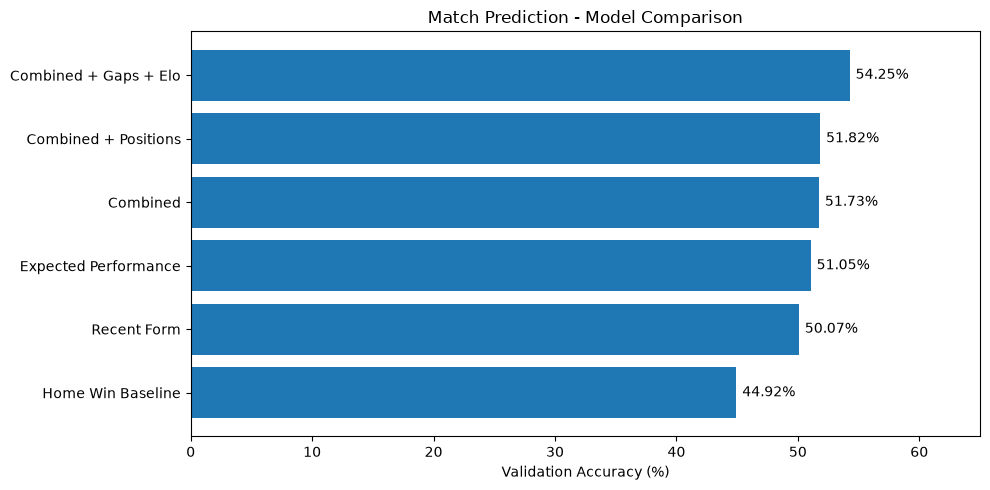

In [22]:
# Collect validation accuracy from previous experiments
model_scores = {
    "Home Win Baseline": (y_val == "w").mean(),
    "Recent Form": accuracy_score(y_val, y_pred_recent),
    "Expected Performance": accuracy_score(y_val, y_pred_expected),
    "Combined": accuracy_score(y_val, y_pred_combined),
    "Combined + Positions": accuracy_score(y_val, y_pred_position),
    "Combined + Gaps + Elo": elo_results.iloc[0]["Accuracy"]
}

# Plot the results
scores = pd.Series(model_scores).sort_values()

plt.figure(figsize=(10, 5))
bars = plt.barh(scores.index, scores.values * 100)

plt.xlabel("Validation Accuracy (%)")
plt.title("Match Prediction - Model Comparison")
plt.xlim(0, 65)

for bar in bars:
    plt.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

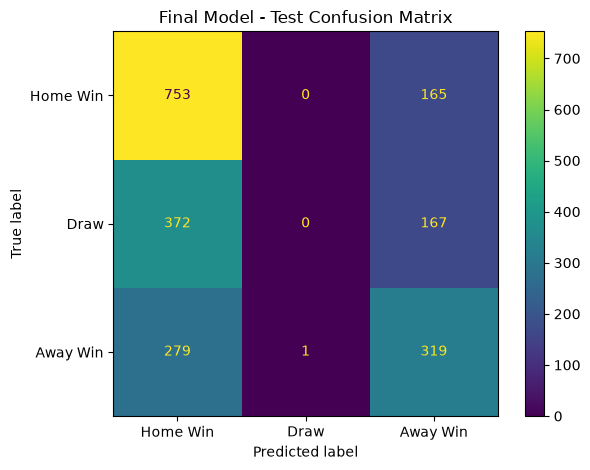

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=["w", "d", "l"],
    display_labels=["Home Win", "Draw", "Away Win"],
    values_format="d"
)

plt.title("Final Model - Test Confusion Matrix")
plt.tight_layout()
plt.show()

### Final Model — Performance by League

After evaluating the final model on the full test dataset, we examine how its prediction accuracy varies across the six European leagues.

For each league, we compare the model's accuracy against a simple baseline that always predicts a home win.

This analysis helps identify where the model performs better or worse and whether its improvement over the baseline is consistent across different leagues.

All results are based on the held-out 2018 test season, without retraining or modifying the model.

In [24]:
# Compare final model performance across leagues

league_test = test[["league", "match_result_home"]].copy()
league_test["prediction"] = test_predictions

league_results = []

for league, games in league_test.groupby("league"):

    league_results.append({
        "League": league,
        "Matches": len(games),
        "Accuracy": (
            games["prediction"] == games["match_result_home"]
        ).mean(),
        "Baseline": (
            games["match_result_home"] == "w"
        ).mean()
    })

league_comparison = pd.DataFrame(league_results)

display(
    league_comparison
    .sort_values("Accuracy", ascending=False)
    .round(3)
)

,League,Matches,Accuracy,Baseline
1,EPL,377,0.586,0.477
0,Bundesliga,304,0.543,0.451
5,Serie_A,379,0.525,0.438
4,RFPL,239,0.523,0.431
3,Ligue_1,379,0.480,0.433
2,La_liga,378,0.476,0.444


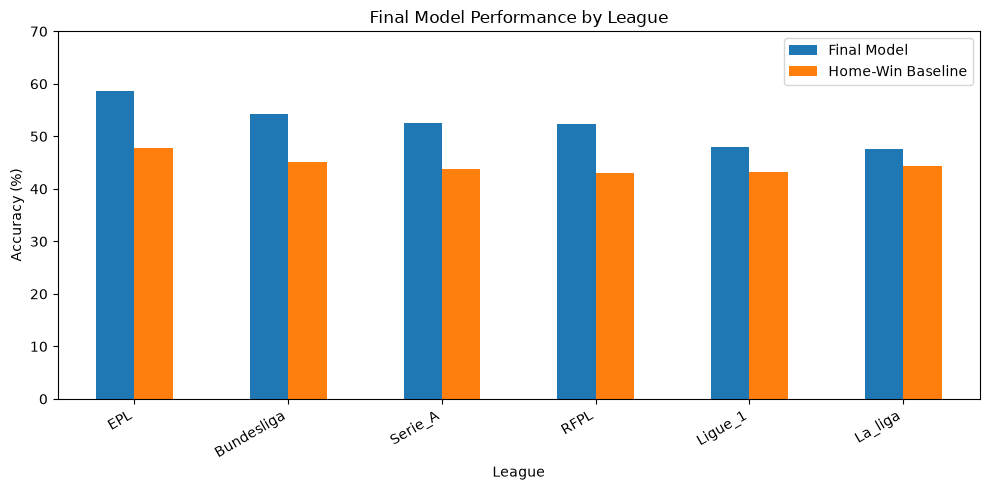

In [25]:
# Visualize model accuracy and baseline across leagues

# Sort leagues by model accuracy
league_plot = league_comparison.sort_values(
    "Accuracy", ascending=False
)

# Convert accuracy values to percentages and create a bar chart
league_plot.set_index("League")[
    ["Accuracy", "Baseline"]
].mul(100).plot(kind="bar", figsize=(10, 5))

plt.title("Final Model Performance by League")
plt.xlabel("League")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 70)
plt.legend(["Final Model", "Home-Win Baseline"])
plt.tight_layout()
plt.savefig("../figures/league_performance.png", dpi=150, bbox_inches="tight")
plt.show()

### League-Level Results and Discussion

The analysis reveals noticeable differences in model performance across leagues.

**Key Findings**

1. **English Premier League:** The model achieved its highest test accuracy of **58.6% across 377 matches**, compared with a home-win baseline of 47.7%. This represents an improvement of **10.9 percentage points**.

2. **Bundesliga:** The model achieved 54.3% accuracy, outperforming its baseline of 45.1%.

3. **La Liga and Ligue 1:** The model performed less effectively, achieving 47.6% and 48.0% accuracy, respectively. The improvement over the baseline was considerably smaller in these leagues.

4. **Performance variation:** The model outperformed the home-win baseline in all six leagues, but the size of the improvement varied substantially.

**Conclusion**

The results suggest that the predictive effectiveness of our features may differ across leagues.

The strong performance in the Premier League is particularly interesting, but this analysis covers only one test season. Therefore, we cannot conclude that the model consistently performs better in England or identify the underlying cause without further investigation.

This highlights the importance of evaluating machine learning models across different segments of the data rather than relying only on overall accuracy.